# **1. Perkenalan dataset**


Dataset ini memberikan gambaran terperinci mengenai perilaku transaksional dan pola aktivitas keuangan yang ideal untuk mengeksplorasi deteksi penipuan dan identifikasi anomali. dataset ini berisi **2.512** sampel data transaksi, yang mencakup berbagai atribut transaksi, demografi pelanggan, dan pola penggunaan. Setiap entri menawarkan wawasan yang komprehensif tentang perilaku transaksi, memungkinkan analisis untuk aplikasi keamanan keuangan dan deteksi penipuan.

Key Features:

* **TransactionID**: Pengidentifikasi alfanumerik unik untuk setiap transaksi.
* **AccountID**: Pengidentifikasi unik untuk setiap akun, dengan beberapa transaksi per akun.
* **TransactionAmount**: Nilai moneter dari setiap transaksi, mulai dari pengeluaran harian yang kecil hingga pembelian yang lebih besar.
* **TransactionDate**: Stempel waktu dari setiap transaksi, mencatat tanggal dan waktu.
* **TransactionType**: Kolom kategorikal yang menunjukkan transaksi 'Kredit' atau 'Debit'.
* **Location**: Lokasi geografis transaksi, diwakili oleh nama kota di Amerika Serikat.
* **DeviceID**: Pengenal alfanumerik untuk perangkat yang digunakan untuk melakukan transaksi.
* **IP Address**: Alamat IPv4 yang terkait dengan transaksi, dengan perubahan sesekali untuk beberapa akun.
* **MerchantID**: Pengenal unik untuk merchant, yang menunjukkan merchant yang disukai dan yang tidak disukai untuk setiap akun.
* **AccountBalance**: Saldo di akun setelah transaksi, dengan korelasi logis berdasarkan jenis dan jumlah transaksi.
* **PreviousTransactionDate**: Stempel waktu dari transaksi terakhir untuk akun, membantu dalam menghitung frekuensi transaksi.
* **Channel**: Saluran yang digunakan untuk melakukan transaksi (misal: Online (contohnya: M-Banking), ATM, Cabang).
* **CustomerAge**: Usia pemilik rekening, dengan pengelompokan logis berdasarkan pekerjaan.
* **CustomerOccupation**: Pekerjaan pemilik rekening (misal: Dokter, Insinyur, Mahasiswa, Pensiunan), yang mencerminkan pola pendapatan.
* **TransactionDuration**: Durasi transaksi dalam hitungan detik, bervariasi berdasarkan jenis transaksi.
* **LoginAttempts**: Jumlah percobaan login sebelum transaksi, dengan nilai yang lebih tinggi menunjukkan potensi anomali.

# **2. Import Library**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer
from sklearn.preprocessing import LabelEncoder
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, classification_report
from sklearn.ensemble import IsolationForest
from scipy.stats import zscore, iqr, mstats, stats
from scipy.cluster.hierarchy import dendrogram, linkage

# **3. Memuat dataset**

In [5]:
df = pd.read_csv("/content/drive/MyDrive/Submission Dicoding/Submission BMLP/Bank Transaction Dataset for Fraud Detection.zip")
df.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **4. Exploratory data Analysis (EDA)**

#### Understanding Data Structured

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   object 
 1   AccountID                2512 non-null   object 
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   object 
 4   TransactionType          2512 non-null   object 
 5   Location                 2512 non-null   object 
 6   DeviceID                 2512 non-null   object 
 7   IP Address               2512 non-null   object 
 8   MerchantID               2512 non-null   object 
 9   Channel                  2512 non-null   object 
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   object 
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBalance          

**Insight :**

Informasi yang dimuat diatas memuat beberapa info terkait dataset yang digunakan sebagai berikut:


* Dataset terdiri dari 2512 entries dan 16 kolom
* Terdiri dari beberapa feature dengan type data yang berbeda yaitu object (terdiri dari 11 feature), Integer (terdiri dari 3 feature), dan float (terdiri dari 2 feature)



#### Check and Handling Missing Values

In [8]:
print("Jumlah data yang hilang:\n")
print(df.isnull().sum())

Jumlah data yang hilang:

TransactionID              0
AccountID                  0
TransactionAmount          0
TransactionDate            0
TransactionType            0
Location                   0
DeviceID                   0
IP Address                 0
MerchantID                 0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
PreviousTransactionDate    0
dtype: int64


#### Check and Handling Data Duplicate

In [9]:
print("Jumlah data Duplikat:", df.duplicated().sum())

Jumlah data Duplikat: 0


#### Statistical Five Summary

In [10]:
df.describe()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2512.000000,2512.000000,2512.000000,2512.000000,2512.000000
mean,297.593778,44.673965,119.643312,1.124602,5114.302966
std,291.946243,17.792198,69.963757,0.602662,3900.942499
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.885000,27.000000,63.000000,1.000000,1504.370000
50%,211.140000,45.000000,112.500000,1.000000,4735.510000
75%,414.527500,59.000000,161.000000,1.000000,7678.820000
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


**Insight :**

Berdasarkan hasil statistik deskriptif yang ditampilkan oleh df.describe(), kita dapat melihat beberapa informasi penting mengenai kolom-kolom numerik dalam dataset.

1. **Transaction Amount**
  
  - Rata-rata jumlah transaksi adalah 297.593
  - Jumlah minimal transaksi adalah 0.2600
  - Jumlah maksimal transaksi adalah 1919.1100
  - Sebagian besar customer melakukan transaksi pada kisaran angka (81.8850 - 414.5275)

2. **Customer Age**

  - Usia customer berkisar antara usia 18 - 80 tahun dengan rata-rata usia customer adalah 44.67 tahun
  - Sebagian besar customer terdapat pada range usia 27 - 59 tahun (quartil ke-1 hingga ke-3)

3. **Transaction Duration**

  - Rata-rata durasi selama transaksi sekitar 119.64 seconds
  - Durasi transaksi paling singkat adalah 10 seconds dan durasi terlama 300 seconds

4. **Account Balance**

  - Rata-rata sisa saldo customer setelah melakukan transaksi terakhir kali adalah 5114.3029
  - Sebagian besar sisa saldo customer setelah melakukan transaksi terakhir kali berkisar pada angka (1504.3700 - 678.8200)

#### Separating Numerical and Categorical Data

In [11]:
# Categorical columns
cat_col = [col for col in df.columns if df[col].dtype == 'object']
print('Categorical columns :',cat_col)
# Numerical columns
num_col = [col for col in df.columns if df[col].dtype != 'object']
print('Numerical columns :',num_col)

Categorical columns : ['TransactionID', 'AccountID', 'TransactionDate', 'TransactionType', 'Location', 'DeviceID', 'IP Address', 'MerchantID', 'Channel', 'CustomerOccupation', 'PreviousTransactionDate']
Numerical columns : ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']


#### View Correlations Using Heatmaps

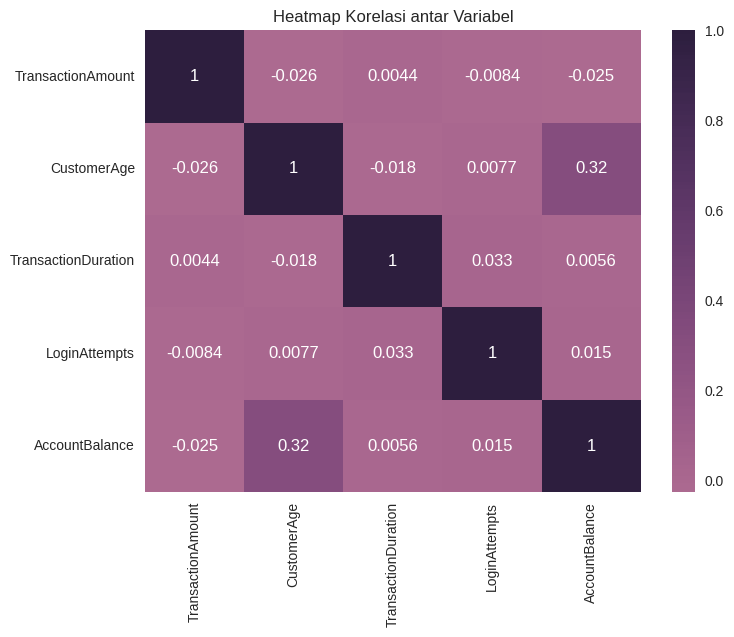

In [12]:
corr_matrix = df[num_col].corr()

# Tampilkan heatmap korelasi
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap=sns.cubehelix_palette(as_cmap=True), center=0)
plt.title("Heatmap Korelasi antar Variabel")
plt.show()

**Insight:**

Angka korelasi di atas menunjukkan keluaran angka yang menunjukkan seberapa korelasi antara dua variabel.

* Angka korelasi yang positif (+) menunjukkan hubungan yang baik antar dua variabel. Hal ini ialah ketika satu variabel mengalami kenaikan mana variabel yang lain ikut mengalami kenaikan.
* Jika angka korelasinya negatif (-) itu artinya jika satu variabel turun maka variabel lain akan naik.
* Jika menunjukkan angka nol (0) maka tidak terdapat korelasi pada kedua variabel tersebut. Namun, jika menunjukkan angka satu (1) maka kedua variabel tersebut menunjukkan korelasi yang sempurna


#### Distribution of Categorical Features

/tmp/ipykernel_495/1907385404.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df[column], palette=custom_palette)
/tmp/ipykernel_495/1907385404.py:8: UserWarning: The palette list has more values (4) than needed (2), which may not be intended.
  sns.countplot(y=df[column], palette=custom_palette)
/tmp/ipykernel_495/1907385404.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df[column], palette=custom_palette)
/tmp/ipykernel_495/1907385404.py:8: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.countplot(y=df[column], palette=custom_palette)
/tmp/ipykernel_495/1907385404.py:8: FutureWarning: 

Passing `palette` without assigni

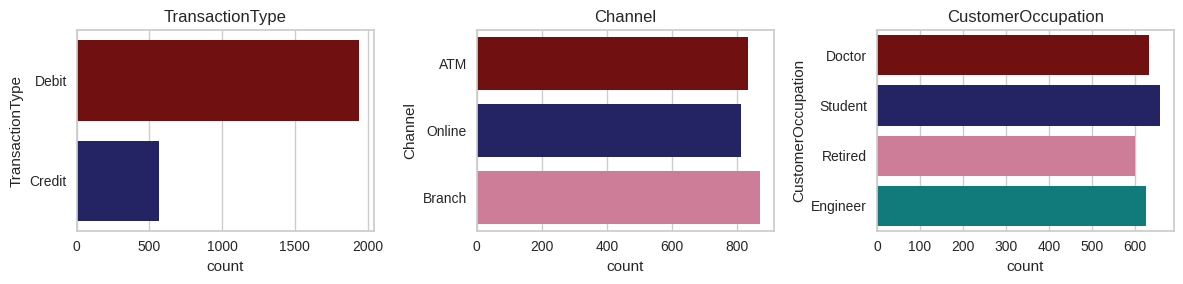

In [13]:
feature = ['TransactionType', 'Channel', 'CustomerOccupation']
custom_palette = ['maroon', 'midnightblue', 'palevioletred', 'darkcyan']
cat_cols = len(feature)
fig, ax = plt.subplots(nrows=1, ncols=cat_cols, figsize=(cat_cols * 4, 3))

for i, column in enumerate(df[feature].columns):
    plt.subplot(1, cat_cols, i + 1)
    sns.countplot(y=df[column], palette=custom_palette)
    ax[i].set_title(column)

plt.tight_layout()
plt.show()

**Insight :**

Hasil pengelompokan data di atas menggunakan kolom kategori untuk menampilkan jumlah dari setiap jenis dari kolom kategori yang lebih dari satu jenis.

# **5. Data Preprocessing**

#### Check and Handling Outliers

/tmp/ipykernel_495/2748492825.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[col], ax=ax[i], palette="Set2")
/tmp/ipykernel_495/2748492825.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[col], ax=ax[i], palette="Set2")
/tmp/ipykernel_495/2748492825.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[col], ax=ax[i], palette="Set2")
/tmp/ipykernel_495/2748492825.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=

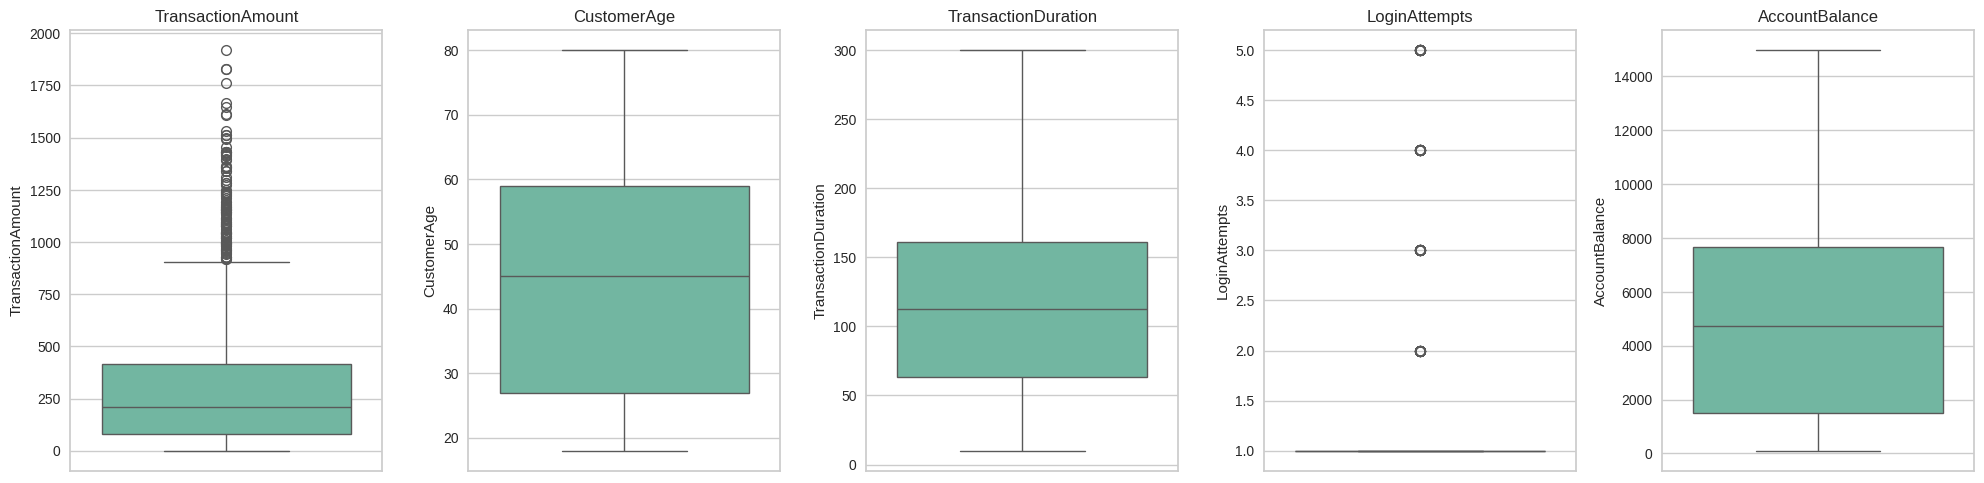

In [14]:
num_cols = len(num_col)
fig, ax = plt.subplots(nrows=1, ncols=num_cols, figsize=(num_cols * 4, 5))

# Loop untuk membuat boxplot di setiap subplot
for i, col in enumerate(num_col):
    sns.boxplot(y=df[col], ax=ax[i], palette="Set2")
    ax[i].set_title(col)

plt.tight_layout()
plt.show()

In [15]:
# Winsorization untuk Amount (mengurangi dampak outliers tanpa menghapus)
features = ["TransactionAmount","LoginAttempts"]
for feature in features:
    df[feature] = mstats.winsorize(df[feature], limits=[0.05, 0.05])

**Insight :**

Beberapa alasan kenapa menggunakan metode winsorized untuk handling outliers:

* Mempertahankan jumlah data, dimana winsorize ini membatasi nilai ekstrem ke persentil tertentu. Hal ini memungkinkan untuk mempertahankan seluruh data, yang penting dalam kasus di mana outlier adalah bagian valid dari distribusi (contohnya seperti transaction amount yang ekstrim dan jauh dari rata-rata)
* Mengurangi dampak outlier tanpa kehilangan informasi penting
* Winsorization membuat data lebih stabil dengan mengurangi varians akibat outlier
* Cocok untuk data yang cenderung skewed

/tmp/ipykernel_495/2748492825.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[col], ax=ax[i], palette="Set2")
/tmp/ipykernel_495/2748492825.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[col], ax=ax[i], palette="Set2")
/tmp/ipykernel_495/2748492825.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[col], ax=ax[i], palette="Set2")
/tmp/ipykernel_495/2748492825.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=

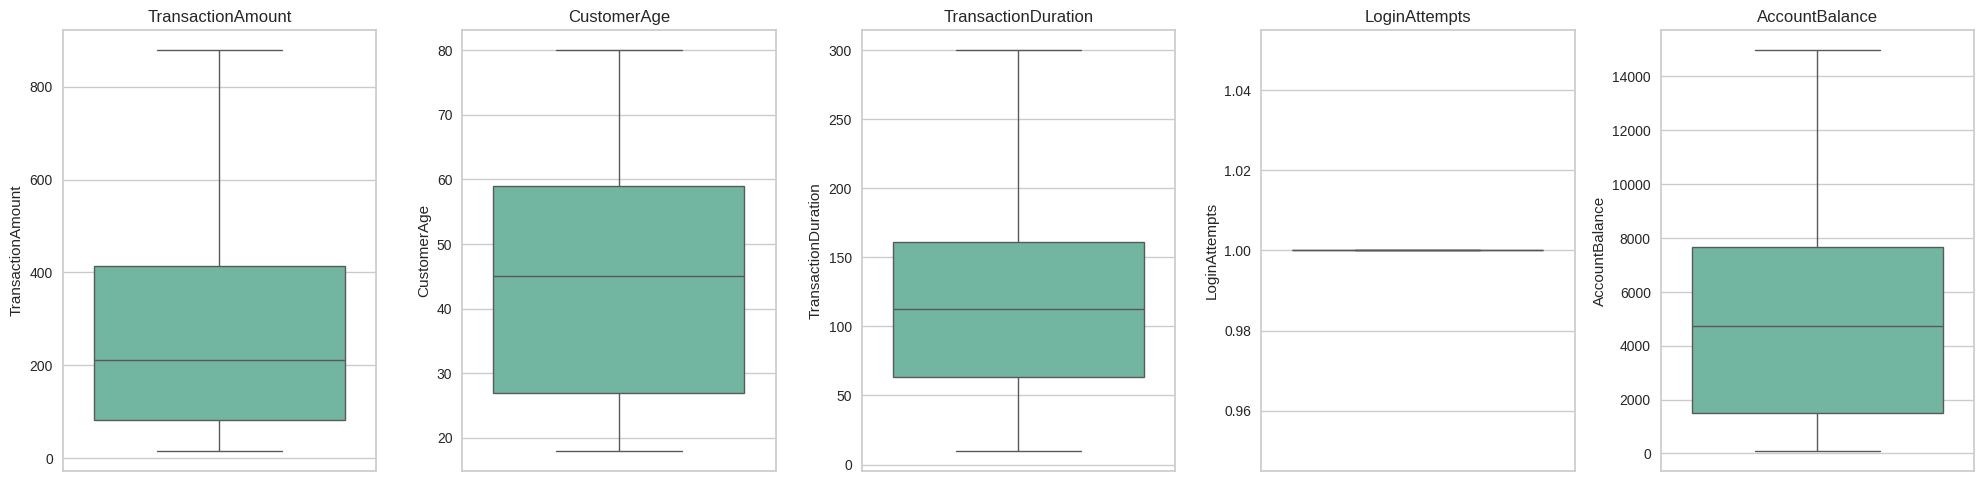

In [16]:
num_cols = len(num_col)
fig, ax = plt.subplots(nrows=1, ncols=num_cols, figsize=(num_cols * 4, 5))

# Loop untuk membuat boxplot di setiap subplot
for i, col in enumerate(num_col):
    sns.boxplot(y=df[col], ax=ax[i], palette="Set2")
    ax[i].set_title(col)

plt.tight_layout()
plt.show()

**Insight :**

Boxplot di atas menunjukkan bahwa outliers sudah tidak terdeteksi lagi.

#### Checking Data Distribution Using Histogram

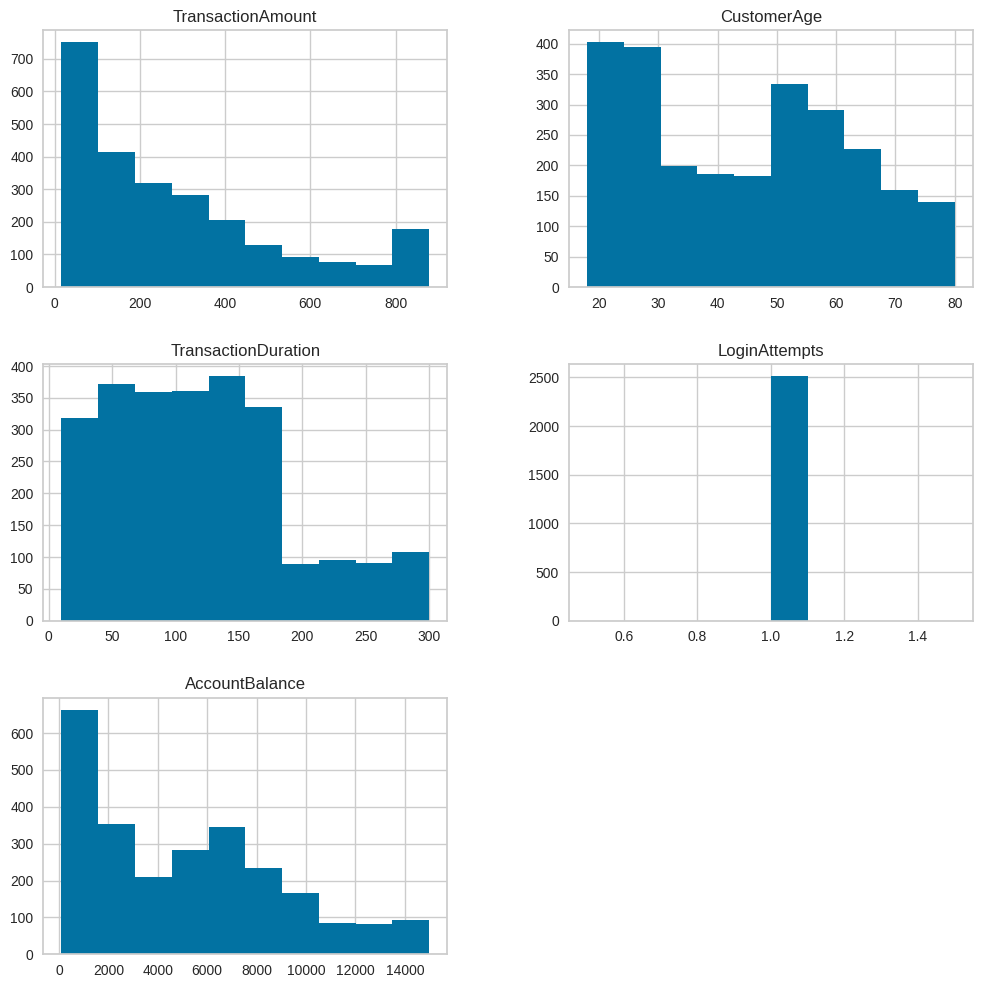

In [17]:
df[num_col].hist(figsize=(12,12))
plt.show()

#### Encoding data Kategorikal

In [18]:
# Membuat objek LabelEncoder
encoders = {}

# Menyimpan encoder untuk setiap kolom kategorikal
cat_col = ['TransactionType', 'Channel', 'CustomerOccupation']
for col in cat_col:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col])  # Transformasi data menjadi numerik
    encoders[col] = encoder  # Simpan encoder untuk kolom ini

# Menampilkan hasil encoding
df.head(10)

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,16.16,2023-04-11 16:29:14,1,San Diego,D000380,162.198.218.92,M015,0,70,0,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,1,Houston,D000051,13.149.61.4,M052,0,68,0,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,1,Mesa,D000235,215.97.143.157,M009,2,19,3,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,1,Raleigh,D000187,200.13.225.150,M002,2,26,3,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,16.16,2023-10-16 17:51:24,0,Atlanta,D000308,65.164.3.100,M091,2,26,3,198,1,7429.40,2024-11-04 08:06:39
5,TX000006,AC00393,92.15,2023-04-03 17:15:01,1,Oklahoma City,D000579,117.67.192.211,M054,0,18,3,172,1,781.68,2024-11-04 08:06:36
6,TX000007,AC00199,16.16,2023-02-15 16:36:48,0,Seattle,D000241,140.212.253.222,M019,0,37,0,139,1,13316.71,2024-11-04 08:10:09
7,TX000008,AC00069,171.42,2023-05-08 17:47:59,0,Indianapolis,D000500,92.214.76.157,M020,1,67,2,291,1,2796.24,2024-11-04 08:10:55
8,TX000009,AC00135,106.23,2023-03-21 16:59:46,0,Detroit,D000690,24.148.92.177,M035,1,51,1,86,1,9095.14,2024-11-04 08:11:14
9,TX000010,AC00385,815.96,2023-03-31 16:06:57,1,Nashville,D000199,32.169.88.41,M007,0,55,0,120,1,1021.88,2024-11-04 08:06:32


In [19]:
# Memisahkan kembali kolom numerik dan kategorikal setelah encoding
encoded_num_col = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
encoded_cat_col = [col for col in encoded_num_col if col in cat_col]
encoded_num_col = [col for col in encoded_num_col if col not in cat_col]

# Output hasil pemisahan
print("Kolom Kategorikal setelah encoding:", encoded_cat_col)
print("Kolom Numerik setelah encoding:", encoded_num_col)

Kolom Kategorikal setelah encoding: ['TransactionType', 'Channel', 'CustomerOccupation']
Kolom Numerik setelah encoding: ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']


#### Scaling Data Using MinMaxScaler()

In [20]:
# Normalisasi menggunakan MinMaxScaler
scaler_minmax1 = MinMaxScaler()
df_normalized = scaler_minmax1.fit_transform(df[encoded_num_col])
df_normalized = pd.DataFrame(df_normalized, columns=df[encoded_num_col].columns)
df_normalized.head(10)

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
0,0.000000,0.838710,0.244828,0.0,0.336832
1,0.417499,0.806452,0.451724,0.0,0.918055
2,0.127691,0.016129,0.158621,0.0,0.068637
3,0.195184,0.129032,0.051724,0.0,0.569198
4,0.000000,0.129032,0.648276,0.0,0.492591
5,0.088107,0.000000,0.558621,0.0,0.045738
6,0.000000,0.306452,0.444828,0.0,0.888330
7,0.180018,0.790323,0.968966,0.0,0.181155
8,0.104433,0.532258,0.262069,0.0,0.604561
9,0.927337,0.596774,0.379310,0.0,0.061884


**Insight :**

untuk data scaling menggunakan MinMaxScaler() untuk menormalisasikan data dikarenakan data yang terdistribusi tidak normal atau data cenderung terlihat skewed

#### Binning (Pengelompokan data)

##### Number of Customer Based On Age


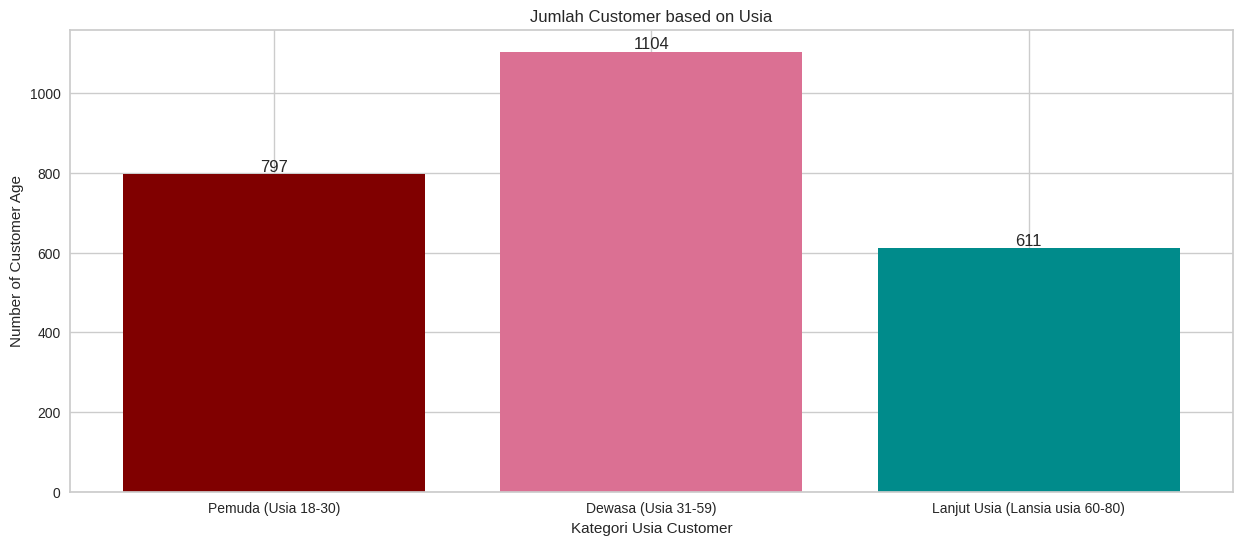

In [21]:
CustomerAge1 = df.CustomerAge[(df.CustomerAge  >= 18) & (df.CustomerAge  <= 30)]
CustomerAge2 = df.CustomerAge[(df.CustomerAge  >= 31) & (df.CustomerAge <= 59)]
CustomerAge3 = df.CustomerAge[(df.CustomerAge  >= 60) & (df.CustomerAge  <= 80)]

# Menyusun data untuk plotting
x = ["Pemuda (Usia 18-30)", "Dewasa (Usia 31-59)", "Lanjut Usia (Lansia usia 60-80)"]
y = [len(CustomerAge1.values), len(CustomerAge2.values), len(CustomerAge3.values)]

# Membuat bar chart untuk distribusi usia customer
plt.figure(figsize=(15, 6))
plt.bar(x, y, color=['maroon','palevioletred', 'darkcyan'])
plt.title("Jumlah Customer based on Usia")
plt.xlabel("Kategori Usia Customer")
plt.ylabel("Number of Customer Age")

# Menambahkan label jumlah customer tiap kategori usia di atas bar
for i in range(len(x)):
  plt.text(i, y[i], y[i], ha='center', va='bottom')

plt.show()

**Insight :**

Dari grafik batang yang ditampilkan di atas, kita tahu bahwa sejumlah customer dari berbagai kategori berdasarkan usia terbagi menjadi tiga.
- Pemuda  : terdapat 797 customer
- Dewasa  : terdapat 1104 customer
- Lansia  : terdapat 611 customer

##### Customer and Their Transaction Amount

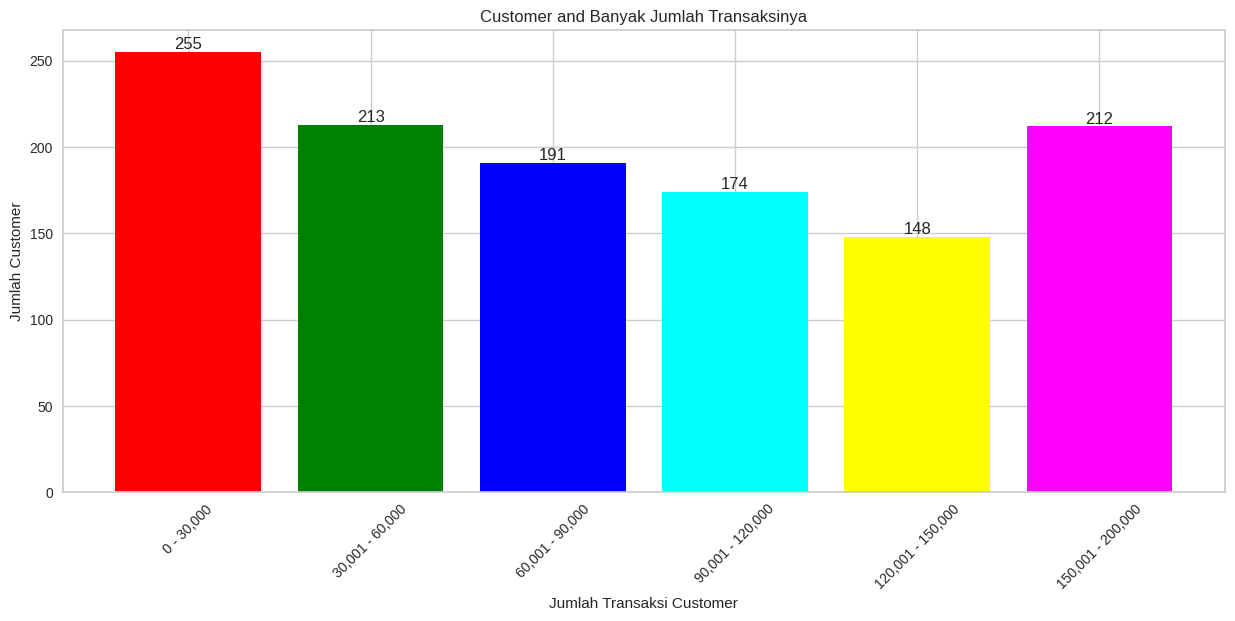

In [22]:
# Mengelompokkan jumlah transaksi pelanggan ke dalam kategori dan menghitung jumlah pelanggan di setiap kategori
ta0_30 = df["TransactionAmount"][(df["TransactionAmount"] >= 0) & (df["TransactionAmount"] <= 30)]
ta31_60 = df["TransactionAmount"][(df["TransactionAmount"] >= 31) & (df["TransactionAmount"] <= 60)]
ta61_90 = df["TransactionAmount"][(df["TransactionAmount"] >= 61) & (df["TransactionAmount"] <= 90)]
ta91_120 = df["TransactionAmount"][(df["TransactionAmount"] >= 91) & (df["TransactionAmount"] <= 120)]
ta121_150 = df["TransactionAmount"][(df["TransactionAmount"] >= 121) & (df["TransactionAmount"] <= 150)]
ta151_200 = df["TransactionAmount"][(df["TransactionAmount"] >= 151) & (df["TransactionAmount"] <= 200)]

# Menyusun data untuk plotting
aix = ["0 - 30,000", "30,001 - 60,000", "60,001 - 90,000", "90,001 - 120,000", "120,001 - 150,000", "150,001 - 200,000"]
aiy = [len(ta0_30.values), len(ta31_60.values), len(ta61_90.values), len(ta91_120.values), len(ta121_150.values), len(ta151_200.values)]

# Membuat bar chart untuk distribusi pendapatan tahunan pelanggan
plt.figure(figsize=(15, 6))
plt.bar(aix, aiy, color=['red', 'green', 'blue', 'cyan', 'yellow', 'magenta'])
plt.title("Customer and Banyak Jumlah Transaksinya")
plt.xlabel("Jumlah Transaksi Customer")
plt.ylabel("Jumlah Customer")
plt.xticks(rotation=45)

# Menambahkan label jumlah pelanggan di atas setiap bar
for i in range(len(aix)):
  plt.text(i, aiy[i], aiy[i], ha='center', va='bottom')

plt.show()

**Insight :**

Berikut adalah penjelasan dari bar chart di atas mengenai banyaknya jumlah transaksi yang dilakukan oleh sejumlah customer:

1. Pada bar warna merah (0-30.00) menunjukkan bahwa ada 255 customer yang melakukan transaksi dengan range jumlah 0-30.000.

2. Pada bar warna hijau (30.001-60.000) menunjukkan bahwa ada 213 customer yang melakukan transaksi dengan range jumlah 30.001-60.000

3. Pada bar warna biru (60.001-90.000) menunjukkan bahwa ada 191 customer yang melakukan transaksi dengan range jumlah 60.001-90.000.

4. Pada bar warna cyan (90.001-120.000) menunjukkan bahwa ada 174 customer yang melakukan transaksi dengan range jumlah 90.001-120.000

5. Pada bar warna kuning (120.001-150.00) menunjukkan bahwa ada 148 customer yang melakukan transaksi dengan range jumlah 120.001-150.000

6. Pada bar warna magenta (150.001-200.000) menunjukkan bahwa ada 212 customer yang melakukan transaksi dengan range jumlah 150.001-200.000

# **6. Pembangunan Model Clustering**

## **a. Pembangunan Model Clustering**

#### K-Means without Feature Selection

In [23]:
optimal_k = 2
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_normalized['cluster_kmeans'] = kmeans.fit_predict(df_normalized)

print("Model training selesai.")

Model training selesai.


**Insight :**

jumlah cluster pada optimal_k sudah ditentukan sendiri yaitu sebanyak 2 cluster karena dalam case ini ingin menganalisis fraud detection dimana terdapat fraud = 1 & non-fraud = 0

In [24]:
silhouette_kmeans1 = silhouette_score(df_normalized, df_normalized['cluster_kmeans'])
print("Silhouette Scores:")
print(f"K-Means Clustering: {silhouette_kmeans1:.4f}")

Silhouette Scores:
K-Means Clustering: 0.5358


**Insight :**

Evaluasi model clustering di atas menggunakan Silhoutte score dikarenakan data yang digunakan adalah dalah unlabled (belum memiliki variabel target).

Silhouette score adalah metrik yang mengukur seberapa baik setiap data point diklasifikasikan dalam cluster-nya sendiri dibandingkan dengan cluster lain. Dimana nilai ini memberikan informasi tentang kualitas clustering dengan memperhitungkan kepadatan dan jarak antar cluster.



## **c. Feature Selection (Opsional)**

#### K-Means with Feature Selection

In [43]:
# Pilih fitur numerik yang relevan
features = ['TransactionAmount', 'TransactionType','TransactionDuration', 'AccountBalance']
X_Selected = df[features]

**Insight :**

Mencoba menerapkan feature selection pada feature selection menggunakan data sebelumnya yang belum di-scaling untuk dapat meningkatkan nilai Silhoutte score menggunakan feature selection feature


In [26]:
# Normalisasi data menggunakan MinMaxScaler (Range [0, 1])
scaler_minmax2 = MinMaxScaler()
df_scaler = scaler_minmax2.fit_transform(X_Selected)
df_scaler = pd.DataFrame(df_scaler, columns=X_Selected.columns)
df_scaler.head(10)

,TransactionAmount,TransactionType,TransactionDuration,AccountBalance
0,0.000000,1.0,0.244828,0.336832
1,0.417499,1.0,0.451724,0.918055
2,0.127691,1.0,0.158621,0.068637
3,0.195184,1.0,0.051724,0.569198
4,0.000000,0.0,0.648276,0.492591
5,0.088107,1.0,0.558621,0.045738
6,0.000000,0.0,0.444828,0.888330
7,0.180018,0.0,0.968966,0.181155
8,0.104433,0.0,0.262069,0.604561
9,0.927337,1.0,0.379310,0.061884


**Insight :**

untuk data scaling menggunakan MinMaxScaler() untuk menormalisasikan data dikarenakan data yang terdistribusi tidak normal atau data cenderung terlihat skewed

In [27]:
# menerapkan PCA ke dalam 2 komponen utama (PC1 & PC2)
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaler)
df_pca = pd.DataFrame(df_pca, columns=['PC1', 'PC2'])

**Insight :**

Alasan menggunakan PCA (Principal Component Analysis) adalah untuk meningkatkan Kinerja Model Clustering, dimana dalam hal ini terjadi karena :
* Algoritma K-Means Clustering tidak bekerja optimal pada dimensi tinggi karena curse of dimensionality.
* Terdapat banyak fitur yang membuat model semakin sulit untuk membentuk cluster yang jelas.

In [28]:
# K-Means
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df_pca['IsFraud'] = kmeans.fit_predict(df_pca)

print("Model training selesai.")

Model training selesai.


In [29]:
silhouette_kmeans2 = silhouette_score(df_pca, df_pca['IsFraud'])
print("Silhouette Scores:")
print(f"K-Means Clustering: {silhouette_kmeans2:.4f}")

Silhouette Scores:
K-Means Clustering: 0.7892


**Insight :**

Silhouette Score 0.7892 menunjukkan bahwa hasil clustering cukup baik dan ada pemisahan yang jelas antara transaksi fraud dan non-fraud.Ini berarti bahwa objek yang dikelompokkan dalam satu klaster memiliki kesamaan yang cukup tinggi, sementara objek di klaster lain memiliki perbedaan yang signifikan. Dalam konteks fraud detection, skor ini menunjukkan bahwa transaksi yang dikategorikan sebagai fraud dan non-fraud memiliki karakteristik yang cukup berbeda, sehingga pemisahan klaster cukup jelas.

## **b. Evaluasi Model Clustering**

#### Membandingkan Silhoutte Score Before and After Feature Selection

In [30]:
print("Silhouette Scores:")
print(f"K-Means Clustering before feature selection: {silhouette_kmeans1:.4f}")
print(f"K-Means Clustering after feature selection: {silhouette_kmeans2:.4f}")

Silhouette Scores:
K-Means Clustering before feature selection: 0.5358
K-Means Clustering after feature selection: 0.7892


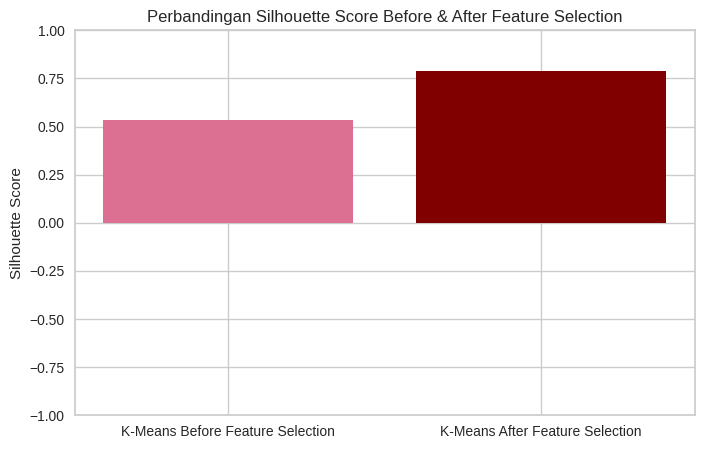

In [31]:
scores = [silhouette_kmeans1, silhouette_kmeans2]
labels = ["K-Means Before Feature Selection", "K-Means After Feature Selection"]

plt.figure(figsize=(8,5))
plt.bar(labels, scores, color=['palevioletred', 'maroon'])
plt.ylabel("Silhouette Score")
plt.title("Perbandingan Silhouette Score Before & After Feature Selection")
plt.ylim(-1, 1)
plt.show()

## **d. Visualisasi Hasil Clustering Using 2D Projection**

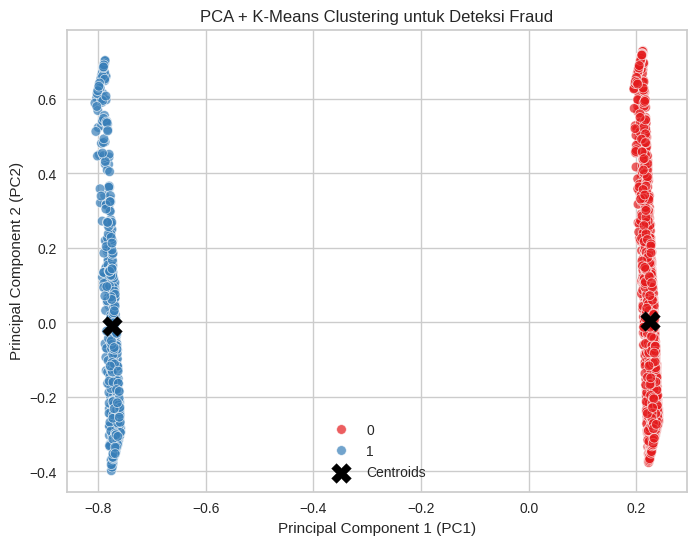

In [32]:
# Dapatkan koordinat centroid
centroids = kmeans.cluster_centers_

# Scatter plot hasil clustering berdasarkan PCA
plt.figure(figsize=(8,6))
sns.scatterplot(x=df_pca['PC1'], y=df_pca['PC2'], hue=df_pca['IsFraud'], palette='Set1', alpha=0.7)

# Tambahkan centroid
plt.scatter(centroids[:, 0], centroids[:, 1], marker='X', s=200, color='black', label='Centroids')

# Label & Title
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('PCA + K-Means Clustering untuk Deteksi Fraud')
plt.legend()
plt.show()

## **e. Analisis dan Interpretasi Hasil Cluster**

### Interpretasi Target

In [33]:
# Menambahkan hasil klastering (label KMeans) sebagai target
df_scaler['IsFraud'] = kmeans.labels_
df_scaler.head()

,TransactionAmount,TransactionType,TransactionDuration,AccountBalance,IsFraud
0,0.000000,1.0,0.244828,0.336832,0
1,0.417499,1.0,0.451724,0.918055,0
2,0.127691,1.0,0.158621,0.068637,0
3,0.195184,1.0,0.051724,0.569198,0
4,0.000000,0.0,0.648276,0.492591,1


### Inverse Data Jika Melakukan Normalisasi/Standardisasi

In [34]:
# Melakukan inversi untuk data yang dinormalisasi pertama kali (sebelum feature selection)
df_inversed = scaler_minmax1.inverse_transform(df_normalized[df[encoded_num_col].columns[:5]])

In [35]:
# Mengonversi hasil inversi kembali ke dalam DataFrame dengan kolom yang sesuai
df_inversed = pd.DataFrame(df_inversed, columns=df[encoded_num_col].columns[:5])
df_inversed.head()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
0,16.16,70.0,81.0,1.0,5112.21
1,376.24,68.0,141.0,1.0,13758.91
2,126.29,19.0,56.0,1.0,1122.35
3,184.50,26.0,25.0,1.0,8569.06
4,16.16,26.0,198.0,1.0,7429.40


In [36]:
# Melakukan inversi untuk data yang dinormalisasi setelah feature selection
df_inversed_selected = scaler_minmax2.inverse_transform(df_scaler[features])
df_inversed_selected = pd.DataFrame(df_inversed_selected, columns=features)
df_inversed_selected.head()

,TransactionAmount,TransactionType,TransactionDuration,AccountBalance
0,16.16,1.0,81.0,5112.21
1,376.24,1.0,141.0,13758.91
2,126.29,1.0,56.0,1122.35
3,184.50,1.0,25.0,8569.06
4,16.16,0.0,198.0,7429.40


In [37]:
# Menggunakan encoder untuk mengembalikan data ke kategori asli
for col in cat_col:
    df[col] = encoders[col].inverse_transform(df[col])

df.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,16.16,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,16.16,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


In [38]:
# Menambah fitur targert
df['IsFraud'] = df_scaler['IsFraud']

In [39]:
# Re-Check for make sure bahwa data sudah kembali ke bentuk semula + targer
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   object 
 1   AccountID                2512 non-null   object 
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   object 
 4   TransactionType          2512 non-null   object 
 5   Location                 2512 non-null   object 
 6   DeviceID                 2512 non-null   object 
 7   IP Address               2512 non-null   object 
 8   MerchantID               2512 non-null   object 
 9   Channel                  2512 non-null   object 
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   object 
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBalance          

#### Agresgasi Features with Label

In [40]:
df.groupby(by=["IsFraud"]).agg({
    "TransactionAmount": ["mean", "sum"],
    "TransactionDuration": ["min", "max", "mean"],
    "AccountBalance": ["sum"],
    "TransactionType": lambda x: x.mode()[0]
}).sort_values(by=("TransactionAmount", "sum"), ascending=False)

TransactionAmount            TransactionDuration                   \
                     mean        sum                 min  max        mean   
IsFraud                                                                     
0              280.556255  545401.36                  10  300  119.716049   
1              294.104349  167051.27                  10  294  119.394366   

        AccountBalance TransactionType  
                   sum        <lambda>  
IsFraud                                 
0           9865508.02           Debit  
1           2981621.03          Credit

## **Analisis Karakteristik Klaster dari Model KMeans**

Berikut adalah analisis karakteristik untuk setiap klaster yang dihasilkan dari model KMeans.

1. Klaster 1 (non-Fraud = 0) didapatkan karena **Jumlah Transaksi** memiliki jumlah transaksi sebanyak **545,401.36** dan nilai rata-rata **280.56** dengan **Durasi Transaksi** memiliki nilai rata-rata selama **119.71** detik, sedangkan **Saldo Akun** memiliki total **9,865,508.02**, yang jauh lebih besar dibandingkan klaster fraud, kemudian untuk **Tipe Transaksi** yang paling sering dilakukan adalah **Debit** yang menunjukkan bahwa jenis transaksi ini lebih sering terjadi pada transaksi non-fraud.  

2. Klaster 2 (Fraud = 1) didapatkan karena **Jumlah Transaksi** memiliki nilai rata-rata **294.10** dengan **Durasi Transaksi** memiliki nilai rata-rata selama **119.39** detik. **Saldo Akun** memiliki total **2,981,621.03**, yang lebih rendah dibandingkan klaster non-fraud, kemudian untuk **Tipe Transaksi** yang paling sering dilakukan adalah **Credit** yang menunjukkan bahwa jenis transaksi ini lebih sering terjadi pada transaksi fraud.

# **7. Mengeksport data**

Menyimpan hasilnya ke dalam file CSV.

In [60]:
df.to_csv('hasil_clustering.csv', index=False)
print("Dataset berhasil disimpan sebagai 'Hasil_Clustering.csv'")

Dataset berhasil disimpan sebagai 'Hasil_Clustering.csv'


### KPI Keamanan Keuangan (Fraud Detection Metrics)**

Bagian ini menghitung dan menampilkan metrik utama untuk mengevaluasi efektivitas sistem deteksi fraud:
* **Total Transactions vs Fraudulent**: Jumlah total transaksi vs transaksi terindikasi fraud.
* **Fraud Rate (%)**: Persentase transaksi fraud dari total transaksi.
* **False Positive Rate (FPR)**: Rasio transaksi aman yang salah dituduh sebagai fraud (karena ini clustering unsupervised tanpa ground truth, asumsikan klaster 1 sebagai prediksi fraud, sedangkan transaksi credit yang umum adalah acuan normal/aman, atau kita definisikan berdasarkan label yang ada).
* **Total Saved Amount**: Estimasi nominal uang yang berhasil diselamatkan dari transaksi yang terindikasi fraud.

In [59]:
# Menghitung metrik KPI
total_transactions = len(df)
total_fraud = df['IsFraud'].sum()
total_non_fraud = total_transactions - total_fraud

# Fraud Rate (%)
fraud_rate = (total_fraud / total_transactions) * 100

# False Positive Rate (FPR)
# Dalam klastering fraud, transaksi 'Credit' pada klaster Fraud (IsFraud=1) dianggap sebagai True Positive.
# Transaksi 'Debit' pada klaster Fraud dianggap salah dituduh (False Positive).
# FPR = FP / (FP + TN) di mana TN adalah Debit di Non-Fraud, FP adalah Debit di Fraud
fp = len(df[(df['IsFraud'] == 1) & (df['TransactionType'] == 'Debit')])
tn = len(df[(df['IsFraud'] == 0) & (df['TransactionType'] == 'Debit')])
fpr = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0

# Total Saved Amount
# Total uang pada transaksi yang terindikasi fraud (IsFraud = 1)
total_saved_amount = df[df['IsFraud'] == 1]['TransactionAmount'].sum()

# Menampilkan KPI
print("="*50)
print(" FINANCIAL SECURITY KPI SUMMARY ".center(50, "="))
print("="*50)
print(f"• Total Transactions       : {total_transactions} transactions")
print(f"• Total Fraudulent Cases   : {total_fraud} transactions")
print(f"• Fraud Rate (%)           : {fraud_rate:.2f}%")
print(f"• False Positive Rate (FPR): {fpr:.2f}%")
print(f"• Total Saved Amount       : ${total_saved_amount:,.2f}")
print("="*50)

========= FINANCIAL SECURITY KPI SUMMARY =========
• Total Transactions       : 2512 transactions
• Total Fraudulent Cases   : 568 transactions
• Fraud Rate (%)           : 22.61%
• False Positive Rate (FPR): 0.00%
• Total Saved Amount       : $167,051.27


### **Grafik Tren & Pola Aktivitas (Data Visualization)**

Bagian ini menyajikan visualisasi mendalam untuk memahami pola dan tren aktivitas fraud:
* **Fraud Over Time**: Grafik garis yang menunjukkan jumlah kasus fraud berdasarkan tanggal transaksi.
* **Risk Score Distribution**: Pengelompokan dan visualisasi tingkat risiko transaksi (Rendah, Sedang, Tinggi).
* **Geographical Risk Map**: Peta interaktif berbasis koordinat geografis/wilayah dengan tingkat fraud tertinggi.

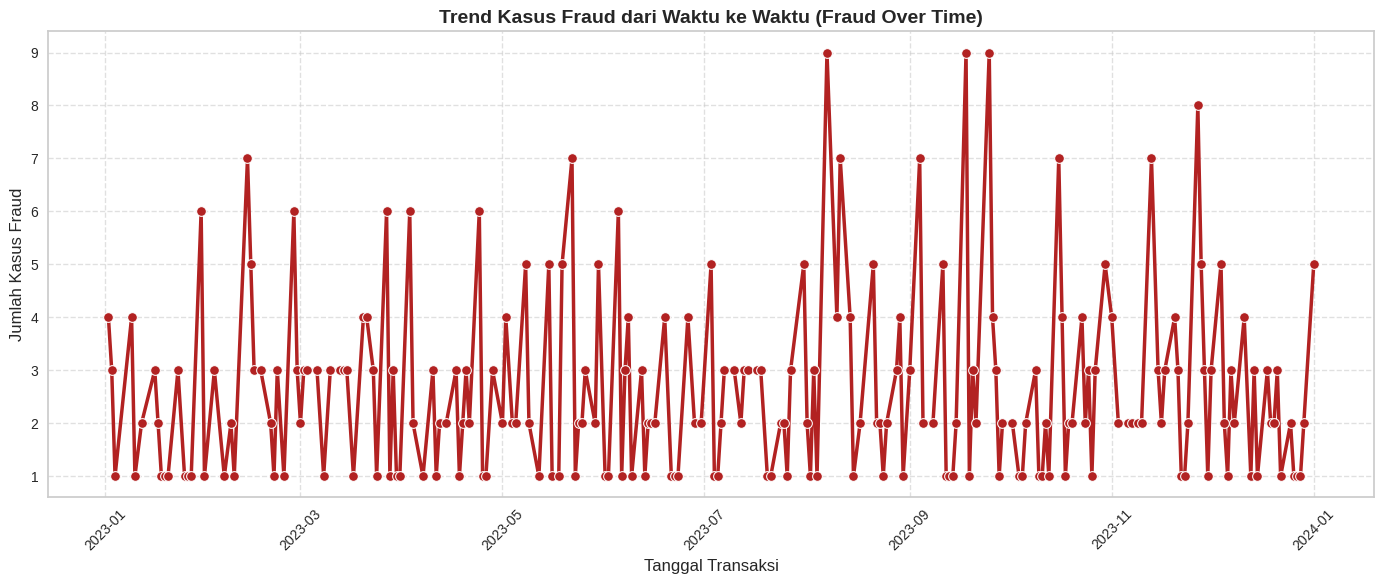

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Memastikan kolom tanggal bertipe datetime
df['TransactionDate'] = pd.to_datetime(df['TransactionDate'])
df['Date'] = df['TransactionDate'].dt.date

# Agregasi kasus fraud per hari
fraud_trend = df[df['IsFraud'] == 1].groupby('Date').size().reset_index(name='FraudCount')

# Visualisasi Fraud Over Time
plt.figure(figsize=(14, 6))
sns.lineplot(data=fraud_trend, x='Date', y='FraudCount', marker='o', color='firebrick', linewidth=2.5)
plt.title('Trend Kasus Fraud dari Waktu ke Waktu (Fraud Over Time)', fontsize=14, fontweight='bold')
plt.xlabel('Tanggal Transaksi', fontsize=12)
plt.ylabel('Jumlah Kasus Fraud', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Menentukan Risk Score Distribution berdasarkan karakteristik transaksi


/tmp/ipykernel_495/33366007.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=risk_counts.index, y=risk_counts.values, ax=axes[1], palette=['forestgreen', 'orange', 'crimson'])


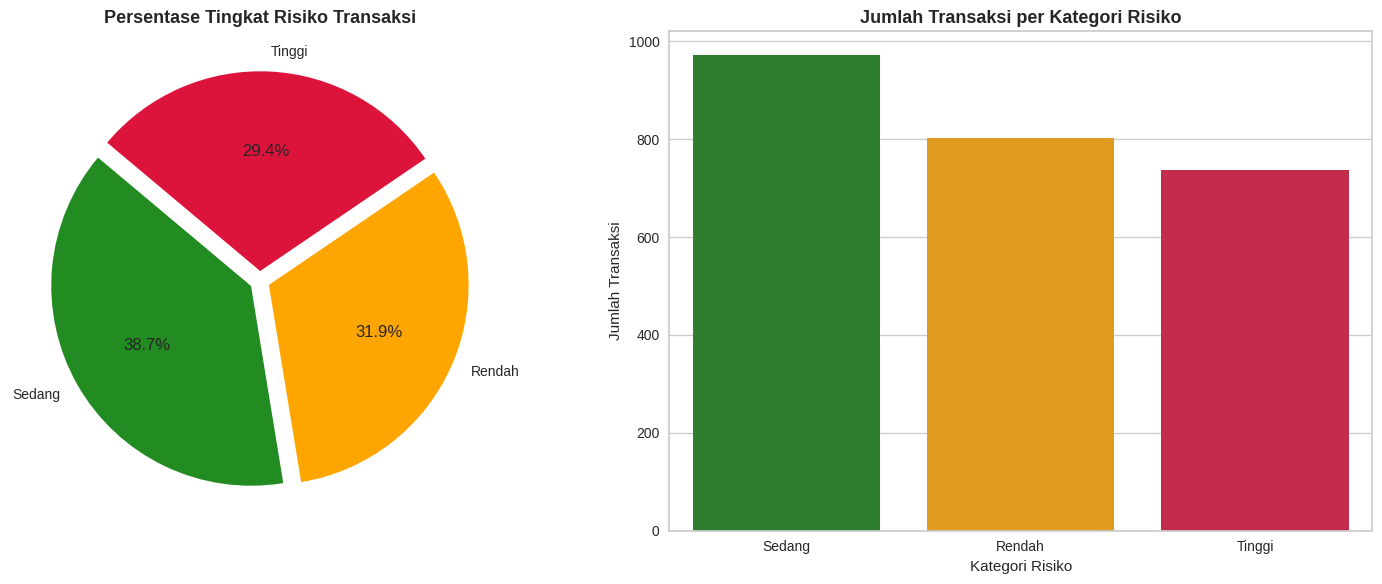

In [46]:
# Kita asumsikan skor risiko didasarkan pada proporsi kedekatan dengan indikator fraud
# (misal: kombinasi jumlah transaksi tinggi dan login attempts)

# Membuat skor risiko sederhana (skala 0 - 100)
# Semakin besar transaksi dan semakin banyak login attempts, semakin tinggi risiko
max_amount = df['TransactionAmount'].max()
risk_score = (0.7 * (df['TransactionAmount'] / max_amount) * 100) + (0.3 * (df['LoginAttempts'] / 5) * 100)
df['RiskScore'] = risk_score

# Mengkategorikan Risk Score
def categorize_risk(score):
    if score < 15:
        return 'Rendah'
    elif score < 35:
        return 'Sedang'
    else:
        return 'Tinggi'

df['RiskCategory'] = df['RiskScore'].apply(categorize_risk)
risk_counts = df['RiskCategory'].value_counts()

# Visualisasi Pie Chart & Bar Chart untuk Risk Score Distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Pie Chart
axes[0].pie(risk_counts, labels=risk_counts.index, autopct='%1.1f%%', startangle=140,
           colors=['forestgreen', 'orange', 'crimson'], explode=(0.05, 0.05, 0.05))
axes[0].set_title('Persentase Tingkat Risiko Transaksi', fontsize=13, fontweight='bold')

# Bar Chart
sns.barplot(x=risk_counts.index, y=risk_counts.values, ax=axes[1], palette=['forestgreen', 'orange', 'crimson'])
axes[1].set_title('Jumlah Transaksi per Kategori Risiko', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Kategori Risiko')
axes[1].set_ylabel('Jumlah Transaksi')

plt.tight_layout()
plt.show()

### Geographical Risk Map


/tmp/ipykernel_495/3279946109.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=geo_risk, x='FraudRate', y='Location', palette='Reds_r')


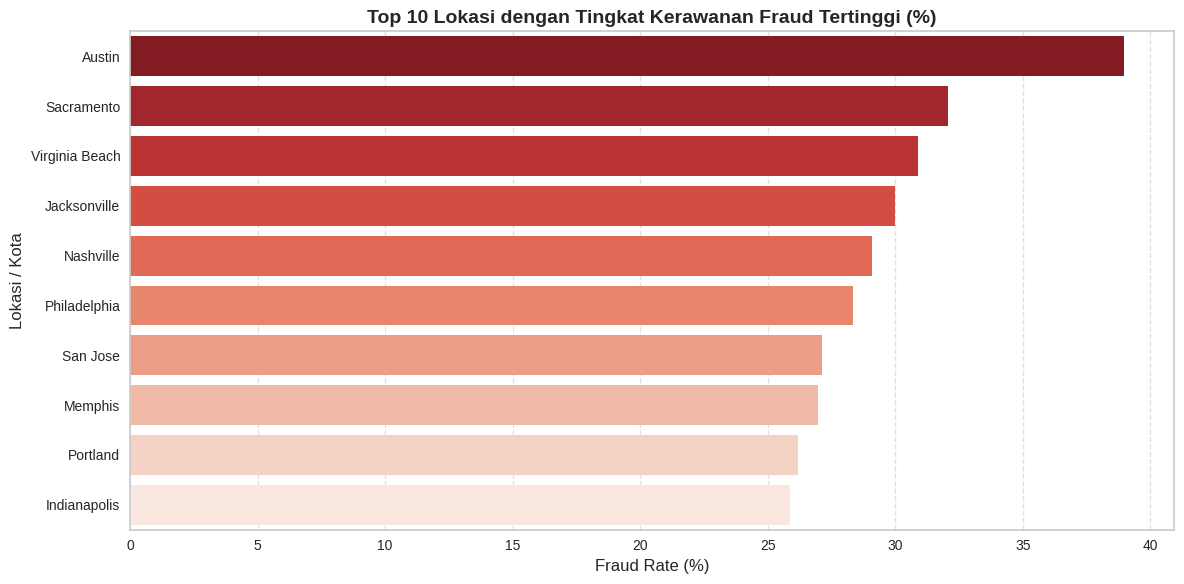

In [47]:
# Menghitung rasio fraud per lokasi
geo_risk = df.groupby('Location').agg(
    Total_Transactions=('TransactionID', 'count'),
    Fraud_Transactions=('IsFraud', 'sum')
).reset_index()

geo_risk['FraudRate'] = (geo_risk['Fraud_Transactions'] / geo_risk['Total_Transactions']) * 100
geo_risk = geo_risk.sort_values(by='FraudRate', ascending=False).head(10)

# Plotting Lokasi dengan Tingkat Fraud Tertinggi
plt.figure(figsize=(12, 6))
sns.barplot(data=geo_risk, x='FraudRate', y='Location', palette='Reds_r')
plt.title('Top 10 Lokasi dengan Tingkat Kerawanan Fraud Tertinggi (%)', fontsize=14, fontweight='bold')
plt.xlabel('Fraud Rate (%)', fontsize=12)
plt.ylabel('Lokasi / Kota', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()